# 03. Paper: TabPFN

논문: Hollmann, Müller, Eggensperger, Hutter, *TabPFN: A Transformer That Solves Small Tabular Classification Problems in a Second* (ICLR 2023), [arXiv:2207.01848](https://arxiv.org/abs/2207.01848).

[`01_pfn`](../01_pfn/02_pfn_paper_walkthrough.ipynb)에서 다룬 PFN을 실제 표 데이터 분류에 쓸 수 있게 확장한 논문입니다. 원 PFN 논문도 표 데이터 실험을 했지만 학습 행 30개짜리 균형 잡힌 이진 분류까지였습니다. TabPFN은 SCM prior와 BNN prior를 섞은 넓은 prior로 Transformer 하나를 학습해서, 학습 행 1,000개, feature 100개, 클래스 10개까지의 데이터셋을 forward pass 한 번으로 분류합니다. 데이터셋마다 하는 학습도, 하이퍼파라미터 튜닝도 없습니다.

SCM과 BNN 자체는 [`01_scm_primer`](01_scm_primer.ipynb)와 [`02_bnn_primer`](02_bnn_primer.ipynb)에서 다뤘습니다. 이 노트북은 논문 내용을 순서대로 정리하고, 재현에 쓴 `src/minipfn/tabpfn/`의 코드로 각 부분을 확인합니다. 논문 규모로 학습해 Table 1을 재현한 결과는 [`04_tabpfn_reproduction`](04_tabpfn_reproduction.ipynb)에 있습니다.

1. PFN 복습 (2절)
2. 아키텍처 변경 (3절, 부록 E)
3. 표 데이터를 위한 prior (4절, 부록 C)
4. 실험 결과 (5절, 부록 B)
5. 한계 (부록 A)
6. 정리

## `minipfn` 불러오기

`01_pfn`과 같은 방식입니다. 이 노트북은 `notebooks/02_tabpfn/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import itertools
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import build_attention_mask, set_seed
from minipfn.tabpfn import prior, spec
from minipfn.tabpfn.model import TabPFNTransformer

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. PFN 복습 — 2절

TabPFN은 PFN의 학습 방식을 그대로 씁니다. prior에서 합성 데이터셋을 뽑고, 일부 행의 정답을 가린 뒤, 나머지 행을 보고 가린 정답을 맞히도록 Transformer를 학습합니다. 논문 2절의 두 식도 [`01_pfn` walkthrough](../01_pfn/02_pfn_paper_walkthrough.ipynb)와 같습니다.

$$
p(y \mid x, D) \;\propto\; \int_{\Phi} p(y \mid x, \phi)\; p(D \mid \phi)\; p(\phi)\; d\phi \tag{1}
$$

$$
\mathcal{L}_{PFN} \;=\; \mathbb{E}_{(\{(x_{test},\, y_{test})\} \,\cup\, D_{train}) \sim p(D)} \big[ -\log q_\theta(y_{test} \mid x_{test}, D_{train}) \big] \tag{2}
$$

$\phi$는 데이터를 만드는 메커니즘 하나입니다. TabPFN에서는 SCM 하나 또는 BNN 하나입니다. 식 (2)의 손실을 줄이면 $q_\theta$가 식 (1)의 PPD에 가까워진다는 것은 원 논문이 보였습니다(`01_pfn` walkthrough 3절). TabPFN 논문의 새로운 점은 이 틀이 아니라, 표 데이터에 맞춘 prior(4절)와 그것을 크게 학습하는 방법(3절)입니다.

![TabPFN Figure 1](images/tabpfn_fig1.png)

*그림: 논문 Figure 1 (Hollmann et al. 2023, [arXiv:2207.01848](https://arxiv.org/abs/2207.01848)). (a) prior-fitting은 한 번만 오프라인으로 하고, 실제 데이터셋에는 forward pass 한 번만 합니다. (b) 학습 행 3개는 서로 attend하고, 테스트 행 $x_4, x_5$는 학습 행에만 attend합니다.*

표 데이터에서 "데이터셋 하나"는 아래 같은 표입니다. 과일 가게에서 무게와 당도로 사과(0)와 배(1)를 구분한다고 해 봅니다. 정답을 아는 학습 행 4개와 정답을 가린 테스트 행 2개를 함께 넣으면, 모델은 `?` 자리의 클래스 확률을 내놓습니다.

In [3]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "y": ["0 (사과)", "0 (사과)", "1 (배)", "1 (배)", "?", "?"],
        "역할": ["학습"] * 4 + ["테스트"] * 2,
    }
)
display(fruit)

,무게(g),당도(brix),y,역할
0,210,13.5,0 (사과),학습
1,190,14.0,0 (사과),학습
2,320,11.0,1 (배),학습
3,290,11.5,1 (배),학습
4,200,13.0,?,테스트
5,310,12.0,?,테스트


원 PFN 논문(Müller et al. 2022)도 이런 표 데이터로 실험했습니다. TabPFN이 무엇을 바꿨는지는 부록 C.2.6에 정리되어 있습니다.

| | 원 PFN의 표 데이터 실험 | TabPFN | 이 노트북 |
|---|---|---|---|
| 학습 행 수 | 30 | 1,000 | |
| feature 수 | 60 | 100 (0으로 채움) | 2.4절 |
| 클래스 | 균형 잡힌 이진 분류 | 최대 10개, 불균형 포함 | 3.4절 |
| prior | BNN | SCM + BNN | 3.2절, 3.3절 |
| attention | 모든 행 쌍 $(n+m)^2$ | $n^2 + n \cdot m$ | 2.2절 |
| 전처리 | 없음 | 이상치 누르기, 추론 때 power transform | 2.5절, 3.5절 |
| 앙상블 | 없음 | feature 열·클래스 번호 회전, power transform 유무 | 2.5절 |

## 2. 아키텍처 변경 — 3절, 부록 E

모델은 원 PFN과 같은 Transformer encoder입니다. 논문 3절은 두 가지만 바꿨다고 말합니다. attention mask를 바꿔 추론을 빠르게 했고, feature 수가 다른 데이터셋을 0으로 채워 한 모델에 넣었습니다. 여기에 추론 때 쓰는 앙상블과 모델 크기까지 차례로 봅니다.

### 2.1 행 하나가 토큰 하나

Transformer에 들어가는 토큰은 표의 행입니다. 학습 행은 feature 벡터 $x$의 임베딩과 정답 $y$의 임베딩을 더해 토큰 하나로 만들고, 테스트 행은 $x$의 임베딩만 씁니다. `TabPFNTransformer.forward`에서 해당 부분은 다음과 같습니다.

```python
h = self.x_encoder(x)                                  # 모든 행: Linear(feature 100개 → 512)
y_emb = self.y_encoder(y_train)                        # 학습 행: 클래스 번호를 실수 하나로 보고 Linear(1 → 512)
h = torch.cat([h[:, :n_train] + y_emb, h[:, n_train:]], dim=1)  # 학습 행에만 y 임베딩을 더한다
```

위의 과일 표를 작은 모델에 넣어 shape을 따라가 봅니다. 맨 앞 차원은 데이터셋 수(batch)입니다. 학습하지 않은 모델이라 확률 값 자체에는 의미가 없습니다.

In [4]:
# 과일 표를 텐서로: 맨 앞 차원 1 = 데이터셋 1개
x_train = torch.tensor([[210, 13.5], [190, 14.0], [320, 11.0], [290, 11.5]]).unsqueeze(0)
y_train = torch.tensor([0, 0, 1, 1]).float().unsqueeze(0)
x_test = torch.tensor([[200, 13.0], [310, 12.0]]).unsqueeze(0)

# feature 2개, 출력 logit 10개(최대 클래스 수)인 작은 모델
tiny = TabPFNTransformer(num_features=2, n_out=10, emsize=8, nhead=2, nhid=16, nlayers=2).eval()
with torch.no_grad():
    logits = tiny(x_train, y_train, x_test)

n_classes = 2
proba = torch.softmax(logits[..., :n_classes], dim=-1)  # 실제 클래스 수만큼만 잘라 softmax

print("x_train:", tuple(x_train.shape), " (데이터셋, 학습 행, feature)")
print("y_train:", tuple(y_train.shape), "    (데이터셋, 학습 행)")
print("x_test: ", tuple(x_test.shape), " (데이터셋, 테스트 행, feature)")
print("logits: ", tuple(logits.shape), "(데이터셋, 테스트 행, 최대 클래스 수)")
print("proba:  ", tuple(proba.shape), " (데이터셋, 테스트 행, 실제 클래스 수)")

x_train: (1, 4, 2)  (데이터셋, 학습 행, feature)
y_train: (1, 4)     (데이터셋, 학습 행)
x_test:  (1, 2, 2)  (데이터셋, 테스트 행, feature)
logits:  (1, 2, 10) (데이터셋, 테스트 행, 최대 클래스 수)
proba:   (1, 2, 2)  (데이터셋, 테스트 행, 실제 클래스 수)


출력은 항상 logit 10개이고, 클래스가 2개인 데이터셋이면 앞의 2개만 씁니다. 학습할 때도 테스트 행의 logit에 cross-entropy를 겁니다(`model.classification_loss`).

### 2.2 attention mask — 부록 E.2

원 PFN은 모든 행 쌍의 attention을 한 번에 계산하고 mask로 막았습니다. 학습 행은 학습 행에만, 테스트 행은 학습 행과 자기 자신에 attend합니다(논문 식 3). TabPFN은 테스트 행이 자기 자신에도 attend하지 않게 바꿨습니다(논문 식 4). 테스트 행 자신의 정보는 residual 연결로 계속 전달됩니다.

학습 행 3개, 테스트 행 2개로 두 mask를 비교합니다. 행은 attend하는 쪽, 열은 attend받는 쪽이고, 1이면 attend합니다. `build_attention_mask`는 `01_pfn` 재현에 쓴 원 PFN의 mask입니다.

In [5]:
n_train, n_test = 3, 2
names = ["train 1", "train 2", "train 3", "test 4", "test 5"]

# 원 PFN (식 3): build_attention_mask는 True = 막음이므로 뒤집는다
pfn_allowed = ~build_attention_mask(n_train, n_test)

# TabPFN (식 4): 모든 행이 학습 행 열만 본다
col = torch.arange(n_train + n_test)
tabpfn_allowed = (col < n_train).expand(n_train + n_test, -1)

print("원 PFN (식 3)")
display(pd.DataFrame(pfn_allowed.int().numpy(), index=names, columns=names))
print("TabPFN (식 4)")
display(pd.DataFrame(tabpfn_allowed.int().numpy(), index=names, columns=names))

원 PFN (식 3)


,train 1,train 2,train 3,test 4,test 5
train 1,1,1,1,0,0
train 2,1,1,1,0,0
train 3,1,1,1,0,0
test 4,1,1,1,1,0
test 5,1,1,1,0,1


TabPFN (식 4)


,train 1,train 2,train 3,test 4,test 5
train 1,1,1,1,0,0
train 2,1,1,1,0,0
train 3,1,1,1,0,0
test 4,1,1,1,0,0
test 5,1,1,1,0,0


식 4에서는 모든 행이 학습 행 열만 봅니다. 그래서 TabPFN 구현은 mask를 쓰지 않고 attention을 두 번 나눠 계산합니다(`TabPFNLayer._attend`). 학습 행끼리의 self-attention 한 번, 테스트 행에서 학습 행으로 가는 cross-attention 한 번이고, 두 번 모두 같은 가중치를 씁니다. 계산하는 attention 점수가 $(n+m)^2$개에서 $n^2 + n \cdot m$개로 줄어듭니다.

In [6]:
rows = []
for n, m in [(1000, 1000), (1000, 100), (100, 1000)]:
    full = (n + m) ** 2  # 원 PFN: 모든 행 쌍
    split = n**2 + n * m  # TabPFN: 학습↔학습 + 테스트→학습
    rows.append(
        {
            "학습 행 n": n,
            "테스트 행 m": m,
            "(n+m)²": full,
            "n²+n·m": split,
            "비율": round(split / full, 3),
        }
    )
display(pd.DataFrame(rows))

,학습 행 n,테스트 행 m,(n+m)²,n²+n·m,비율
0,1000,1000,4000000,2000000,0.500
1,1000,100,1210000,1100000,0.909
2,100,1000,1210000,110000,0.091


비율은 $n/(n+m)$입니다. 학습 행과 테스트 행이 같은 수면 절반으로 줄고, 테스트 행이 많을수록 더 많이 줄어듭니다.

### 2.3 mask가 보장하는 두 성질

이 mask와 위치 인코딩이 없다는 점 때문에 두 성질이 생깁니다.

1. 학습 행의 순서를 바꿔도 예측이 같습니다. 학습 데이터를 집합으로 다룹니다.
2. 테스트 행 하나의 예측은 다른 테스트 행과 무관합니다. 그래서 테스트 행을 한 번에 몇 개를 넣든 결과가 같습니다.

무작위 가중치 모델로 확인합니다. `TabPFNTransformer`는 v1처럼 attention 출력과 FFN 마지막 층을 0으로 초기화합니다. 이 상태에서는 attention이 아무 일도 하지 않아 확인하는 의미가 없으므로, 모든 가중치를 무작위 값으로 바꾼 뒤 확인합니다. 비교용으로 학습 행 하나의 정답을 바꾼 경우도 함께 봅니다. 이때는 예측이 달라져야 합니다.

In [7]:
torch.manual_seed(0)
model = TabPFNTransformer(num_features=5, n_out=3, emsize=16, nhead=2, nhid=32, nlayers=2).eval()
for p in model.parameters():
    nn.init.normal_(p, std=0.5)  # 0으로 초기화된 층도 attention이 일하도록 무작위 값으로

x_tr = torch.randn(1, 20, 5)  # 학습 행 20개
y_tr = torch.randint(0, 3, (1, 20)).float()
x_te = torch.randn(1, 6, 5)  # 테스트 행 6개

with torch.no_grad():
    base = model(x_tr, y_tr, x_te)

    # 성질 1: 학습 행 순서 바꾸기
    perm = torch.randperm(20)
    shuffled = model(x_tr[:, perm], y_tr[:, perm], x_te)

    # 성질 2: 테스트 행을 하나씩 따로 넣기
    one_by_one = [model(x_tr, y_tr, x_te[:, j : j + 1]) for j in range(6)]
    one_by_one = torch.cat(one_by_one, dim=1)

    # 비교용: 학습 행 하나의 정답만 바꾸기
    y_changed = y_tr.clone()
    y_changed[0, 0] = (y_changed[0, 0] + 1) % 3
    changed = model(x_tr, y_changed, x_te)

checks = {
    "학습 행 순서를 바꿈": shuffled,
    "테스트 행을 하나씩 넣음": one_by_one,
    "학습 행 하나의 정답을 바꿈 (비교용)": changed,
}
display(
    pd.DataFrame(
        {
            "원래 logit과의 최대 차이": {
                k: f"{(v - base).abs().max().item():.2e}" for k, v in checks.items()
            }
        }
    )
)

,원래 logit과의 최대 차이
학습 행 순서를 바꿈,4.77e-07
테스트 행을 하나씩 넣음,6.56e-07
학습 행 하나의 정답을 바꿈 (비교용),8.71e-03


앞의 두 경우는 차이가 float 반올림 오차 수준이고, 정답을 바꾼 경우만 크게 달라집니다. 학습한 모델이 아니어도 구조만으로 두 성질이 성립합니다.

### 2.4 feature 수가 다른 데이터셋 — 부록 E.2

`x_encoder`는 입력 크기가 100으로 고정된 Linear입니다. feature가 $k$개($k < 100$)인 데이터셋은 나머지 열을 0으로 채우고, 쓴 열은 $100/k$배 합니다.

작은 예로 보기 위해 최대 feature 수를 6으로 줄이고, feature 3개짜리 표를 넣어 봅니다. $6/3 = 2$배가 됩니다.

In [8]:
max_features = 6  # 실제 TabPFN은 100
small = pd.DataFrame({"f1": [0.5, -1.2, 0.7], "f2": [1.0, 0.3, -1.3], "f3": [-0.4, 0.9, -0.5]})
k = small.shape[1]

scaled = small * (max_features / k)  # 쓴 열을 6/3 = 2배
padded = scaled.copy()
for j in range(k + 1, max_features + 1):
    padded[f"f{j}"] = 0.0  # 나머지 열은 0으로 채운다

print(f"원래 표 (feature {k}개)")
display(small)
print(f"모델 입력 (열 {max_features}개, 쓴 열은 {max_features / k:g}배)")
display(padded)

원래 표 (feature 3개)


,f1,f2,f3
0,0.5,1.0,-0.4
1,-1.2,0.3,0.9
2,0.7,-1.3,-0.5


모델 입력 (열 6개, 쓴 열은 2배)


,f1,f2,f3,f4,f5,f6
0,1.0,2.0,-0.8,0.0,0.0,0.0
1,-2.4,0.6,1.8,0.0,0.0,0.0
2,1.4,-2.6,-1.0,0.0,0.0,0.0


왜 $100/k$배 할까요? 0인 열이 많을수록 행 전체 값의 크기가 작아지기 때문입니다. 표준화한 feature를 $k$개 쓰고 나머지를 0으로 채웠을 때, 100열 전체에서 $|x|$의 평균을 비교합니다.

In [9]:
rng = np.random.default_rng(0)
rows = []
for k in [1, 3, 10, 30, 100]:
    x = rng.standard_normal((1000, k))  # 표준화한 feature k개, 행 1,000개
    x_padded = np.concatenate([x, np.zeros((1000, 100 - k))], axis=1)
    x_scaled = x_padded * (100 / k)
    rows.append(
        {
            "쓴 feature k": k,
            "0으로만 채움": round(np.abs(x_padded).mean(), 3),
            "0으로 채우고 100/k배": round(np.abs(x_scaled).mean(), 3),
        }
    )
display(pd.DataFrame(rows))

,쓴 feature k,0으로만 채움,0으로 채우고 100/k배
0,1,0.008,0.777
1,3,0.024,0.811
2,10,0.080,0.799
3,30,0.240,0.801
4,100,0.797,0.797


0으로만 채우면 feature가 적을수록 입력이 작아지고, $100/k$배 하면 feature 수와 상관없이 100열 평균 크기가 같아집니다(표준정규분포의 $E|x| \approx 0.80$). 학습 때 prior 데이터에도(`TabPFNPrior.sample_group`의 4단계), 추론 때 실제 데이터에도(`inference._Preprocessor._finish`의 마지막 줄) 같은 변환을 합니다.

### 2.5 추론 때의 앙상블 — 3절, 부록 C.2.6

논문의 TabPFN 결과는 같은 데이터셋을 조금씩 바꿔 forward pass를 32번 한 결과의 평균입니다. 바꾸는 방법은 세 가지입니다.

1. **feature 열 번호 회전**: 열 순서를 $[x_1, x_2, x_3, x_4] \to [x_3, x_4, x_1, x_2]$처럼 돌립니다(논문 각주 10).
2. **클래스 번호 회전**: 클래스 0, 1, 2를 1, 2, 0처럼 돌립니다. 출력 확률은 원래 번호로 되돌린 뒤 평균합니다.
3. **power transform(Yeo-Johnson) 적용 여부**: 한쪽으로 꼬리가 긴 feature를 정규분포에 가깝게 폅니다.

feature가 $k$개, 클래스가 $j$개면 가능한 조합은 $2kj$개입니다. 32가 이보다 크면 $2kj$개만 씁니다. 학습 때도 열과 클래스 번호를 돌리므로 모델이 이 회전에 무관해지도록 배우기는 하지만, 완전히 무관하지는 않아서 앙상블이 도움이 됩니다(논문 각주 1).

클래스 번호 회전을 작은 예로 따라가 봅니다. 클래스 3개인 데이터셋에서 학습 행의 정답을 1칸 돌려 넣고, 테스트 행 하나에 대해 모델이 아래 확률을 냈다고 해 봅니다(설명용으로 정한 값).

In [10]:
n_classes, shift = 3, 1

# 1단계: 학습 행의 정답을 1칸 돌려서 넣는다 (0→1, 1→2, 2→0)
y_original = np.array([0, 1, 2, 2, 0])
y_rotated = (y_original + shift) % n_classes
display(pd.DataFrame({"원래 정답": y_original, "돌린 정답 (모델 입력)": y_rotated}))

# 2단계: 모델은 돌린 번호 기준으로 확률을 낸다 (설명용 값)
proba_rotated = np.array([0.1, 0.7, 0.2])

# 3단계: 원래 클래스 c는 돌린 번호 (c + 1) % 3이었으므로 그 자리의 확률을 가져온다
proba_original = np.array([proba_rotated[(c + shift) % n_classes] for c in range(n_classes)])
display(
    pd.DataFrame(
        {"돌린 번호 기준 확률": proba_rotated, "원래 번호로 되돌린 확률": proba_original},
        index=[f"클래스 {c}" for c in range(n_classes)],
    )
)

,원래 정답,돌린 정답 (모델 입력)
0,0,1
1,1,2
2,2,0
3,2,0
4,0,1


,돌린 번호 기준 확률,원래 번호로 되돌린 확률
클래스 0,0.1,0.7
클래스 1,0.7,0.2
클래스 2,0.2,0.1


돌린 번호 1의 확률 0.7은 원래 클래스 0의 확률입니다. 앙상블 멤버마다 이렇게 되돌린 다음 평균합니다. 실제 구현(`inference.TabPFNClassifier`)은 확률 대신 logit을 되돌려 평균한 뒤 softmax합니다.

32개 멤버는 `inference.TabPFNClassifier.fit`에서 이렇게 고릅니다. feature 4개, 클래스 3개인 데이터셋이면 조합이 $2 \times 4 \times 3 = 24$개라 24개만 씁니다.

In [11]:
k, n_classes, n_ensemble, seed = 4, 3, 32, 0

# inference.TabPFNClassifier.fit과 같은 순서로 멤버를 고른다
torch.manual_seed(seed)
feature_shifts = torch.randperm(k).tolist()
class_shifts = torch.randperm(n_classes).tolist()
shift_pairs = list(itertools.product(class_shifts, feature_shifts))  # 클래스 회전 × 열 회전
random.Random(seed).shuffle(shift_pairs)
members = list(itertools.product(shift_pairs, ["none", "power_all"]))[:n_ensemble]

print(f"가능한 조합 2·k·j = {2 * k * n_classes}, 쓰는 멤버 수 = {len(members)}")
display(
    pd.DataFrame(
        [{"클래스 회전": c, "열 회전": f, "변환": t} for (c, f), t in members[:6]],
        index=[f"멤버 {i}" for i in range(6)],
    )
)

가능한 조합 2·k·j = 24, 쓰는 멤버 수 = 24


,클래스 회전,열 회전,변환
멤버 0,0,1,none
멤버 1,0,1,power_all
멤버 2,1,1,none
멤버 3,1,1,power_all
멤버 4,1,0,none
멤버 5,1,0,power_all


power transform은 집값이나 소득처럼 오른쪽 꼬리가 긴 feature를 위한 것입니다. prior 데이터는 신경망 출력을 표준화한 값이라 이런 꼬리가 드물어서, 추론 때 실제 데이터를 prior 데이터와 비슷한 모양으로 바꿔 줍니다(부록 C.2.1).

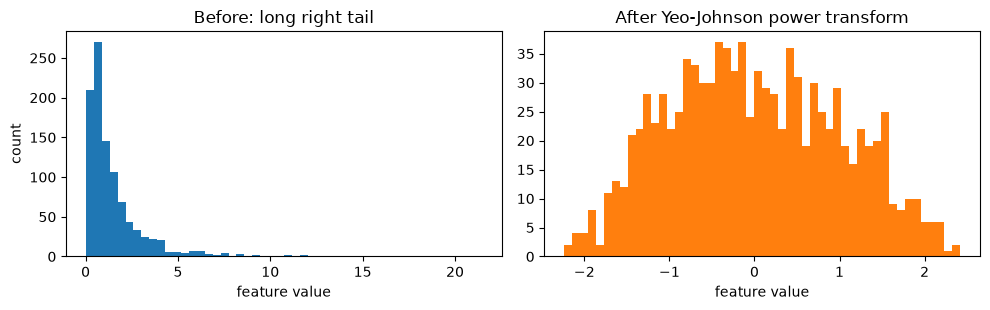

In [12]:
from sklearn.preprocessing import PowerTransformer

rng = np.random.default_rng(0)
skewed = rng.lognormal(mean=0.0, sigma=1.0, size=(1000, 1))  # 오른쪽 꼬리가 긴 feature
transformed = PowerTransformer(method="yeo-johnson", standardize=True).fit_transform(skewed)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(skewed[:, 0], bins=50, color="C0")
axes[0].set_title("Before: long right tail")
axes[1].hist(transformed[:, 0], bins=50, color="C1")
axes[1].set_title("After Yeo-Johnson power transform")
for ax in axes:
    ax.set_xlabel("feature value")
axes[0].set_ylabel("count")
plt.tight_layout()
plt.show()

### 2.6 모델 크기와 학습 — 부록 E.1, E.3

| 항목 | 논문 |
|---|---|
| Transformer | 12층, 임베딩 512, FFN 1,024, head 4 |
| 파라미터 수 | 25.82M |
| 학습 | 18,000 step × batch 512 = 합성 데이터셋 9,216,000개 |
| 학습 시간 | RTX 2080 Ti 8장에서 20시간 |
| 최적화 | Adam, linear warmup + cosine, lr은 {0.001, 0.0003, 0.0001} 중 마지막 학습 loss가 가장 낮은 것 |

논문은 학습 곡선이 데이터셋 약 1,000만 개에서 평평해지고, prior가 매우 다양한 데이터셋을 만들어서 곡선이 많이 출렁였다고 적었습니다(E.3). 이 저장소는 같은 규모를 H100 8장에서 2시간 5분에 학습했습니다(`04` 노트북).

논문 크기로 모델을 만들어 파라미터 수를 부분별로 세어 봅니다.

In [13]:
paper_model = TabPFNTransformer()  # 기본값 = 논문 크기 (spec.py)

parts = {
    "x_encoder (100 → 512)": paper_model.x_encoder,
    "y_encoder (1 → 512)": paper_model.y_encoder,
    "Transformer 층 12개": paper_model.layers,
    "decoder (512 → 1024 → 10)": paper_model.decoder,
}
counts = {name: sum(p.numel() for p in m.parameters()) for name, m in parts.items()}
counts["합계"] = paper_model.num_parameters()
display(pd.DataFrame({"파라미터 수": {k: f"{v:,}" for k, v in counts.items()}}))

,파라미터 수
x_encoder (100 → 512),"51,712"
y_encoder (1 → 512),"1,024"
Transformer 층 12개,"25,233,408"
decoder (512 → 1024 → 10),"535,562"
합계,"25,821,706"


합계 25,821,706개로 논문의 25.82M과 같습니다. 대부분이 Transformer 층에 있고, 층 하나에 attention 약 105만 개, FFN 약 105만 개입니다.

## 3. 표 데이터를 위한 prior — 4절

PFN은 prior의 PPD를 근사할 뿐이므로, 성능은 prior가 정합니다. 실제 표 데이터와 닮은 데이터셋을 prior가 얼마나 넓게 만드느냐가 핵심입니다. 4절은 네 가지 아이디어로 prior를 만듭니다.

- 4.1 하이퍼파라미터도 분포에서 뽑는다
- 4.2 단순한 구조가 더 자주 나오게 한다
- 4.3, 4.4 SCM과 BNN으로 데이터를 만든다
- 4.5 연속값 target을 클래스로 바꾼다

부록 C.2는 여기에 표 데이터의 특성(범주형 feature, 상관된 feature 등)을 더합니다(3.5절). 수치는 논문 부록 E.4(Table 5)와 공식 v1 코드에서 가져와 `spec.py`에 모아 둔 값을 씁니다. 둘이 다르면 공개 체크포인트를 만든 v1 코드를 따랐습니다.

### 3.1 확률적 모델과 단순성 — 4.1, 4.2절

보통은 층 수, 은닉 노드 수, 활성화 함수 같은 하이퍼파라미터를 탐색해 값 하나를 고릅니다. TabPFN의 prior는 값을 고르지 않고 분포를 둡니다. 데이터셋을 만들 때마다 하이퍼파라미터부터 새로 뽑으므로, PFN이 근사하는 PPD는 하이퍼파라미터에 대해서도 적분한 것이 됩니다(4.1절). 4.4절의 SCM·BNN 섞기도 같은 생각을 prior 종류까지 넓힌 것입니다.

그래서 데이터셋 하나는 세 단계로 만듭니다.

1. 하이퍼파라미터를 뽑습니다. 층 수, 노드 수, 활성화 함수, SCM인지 BNN인지 등입니다.
2. 그 하이퍼파라미터로 정한 구조에서 신경망 가중치를 뽑습니다. 이것이 메커니즘 $\phi$ 하나입니다.
3. $\phi$로 행을 만듭니다.

v1 구현은 1단계를 데이터셋 8개("그룹")마다 한 번 하고, 2단계는 데이터셋마다 합니다. `prior.sample_group_hyperparameters`로 그룹 세 개의 하이퍼파라미터를 뽑아 봅니다.

In [14]:
def prior_kind(hp: dict) -> str:
    if not hp["use_mlp"]:
        return "GP"
    return "SCM" if hp["is_causal"] else "BNN"


rng = np.random.default_rng(3)
groups = [
    prior.sample_group_hyperparameters(rng, spec.MAX_CLASSES, spec.MAX_FEATURES) for _ in range(3)
]
display(
    pd.DataFrame(
        {
            "prior": [prior_kind(hp) for hp in groups],
            "층 수": [hp["num_layers"] for hp in groups],
            "층당 노드 수": [hp["prior_mlp_hidden_dim"] for hp in groups],
            "활성화 함수": [hp["prior_mlp_activations"] for hp in groups],
            "간선 dropout": [round(hp["prior_mlp_dropout_prob"], 3) for hp in groups],
            "노이즈 std": [round(hp["noise_std"], 4) for hp in groups],
            "가중치 std": [round(hp["init_std"], 3) for hp in groups],
            "feature 수": [hp["num_features_used"] for hp in groups],
            "클래스 수 상한": [hp["num_classes"] for hp in groups],
        },
        index=["그룹 1", "그룹 2", "그룹 3"],
    )
)

,prior,층 수,층당 노드 수,활성화 함수,간선 dropout,노이즈 std,가중치 std,feature 수,클래스 수 상한
그룹 1,BNN,3,4,tanh,0.558,0.0263,0.764,48,3
그룹 2,SCM,3,5,relu,0.129,0.0945,0.973,78,5
그룹 3,SCM,5,51,identity,0.474,0.0136,4.280,67,9


하이퍼파라미터 하나도 두 단계로 뽑습니다. 예를 들어 층 수는 감마분포에서 뽑는데, 그 감마분포의 모양 $\alpha$와 평균(scale)부터 무작위로 정합니다(v1 `meta_gamma`). 분포의 모수를 먼저 뽑고 그 분포에서 값을 뽑으므로 "meta" 분포라고 부릅니다. 층 수를 5번 뽑으며 단계별 값을 봅니다.

In [15]:
hp_layers = spec.MLP_HYPERPARAMETERS["num_layers"]  # max_alpha 2, max_scale 3, 하한 2
rng = np.random.default_rng(0)
rows = []
for _ in range(5):
    # 1단계: 감마분포의 모수를 뽑는다
    alpha = np.exp(rng.uniform(0.0, np.log(hp_layers["max_alpha"])))  # 모양: 1 ~ 2
    scale = rng.uniform(0.0, hp_layers["max_scale"])  # 평균: 0 ~ 3
    # 2단계: 그 감마분포에서 값을 뽑는다 (평균이 scale이 되도록 θ = scale / α)
    draw = rng.gamma(alpha, scale / alpha)
    # 3단계: 반올림하고 하한 2를 더한다
    n_layers = hp_layers["lower_bound"] + round(draw)
    rows.append(
        {
            "α": round(alpha, 2),
            "scale": round(scale, 2),
            "감마 값": round(draw, 2),
            "층 수": n_layers,
        }
    )
display(pd.DataFrame(rows))

,α,scale,감마 값,층 수
0,1.56,0.81,1.08,3
1,1.76,2.74,5.63,8
2,1.46,2.81,1.12,3
3,1.81,0.10,0.02,2
4,1.82,1.62,1.83,4


4.2절의 단순성(Occam's razor)은 이 분포의 모양으로 들어갑니다. 하이퍼파라미터를 20,000번 뽑아 보면 작은 그래프가 훨씬 자주 나옵니다.

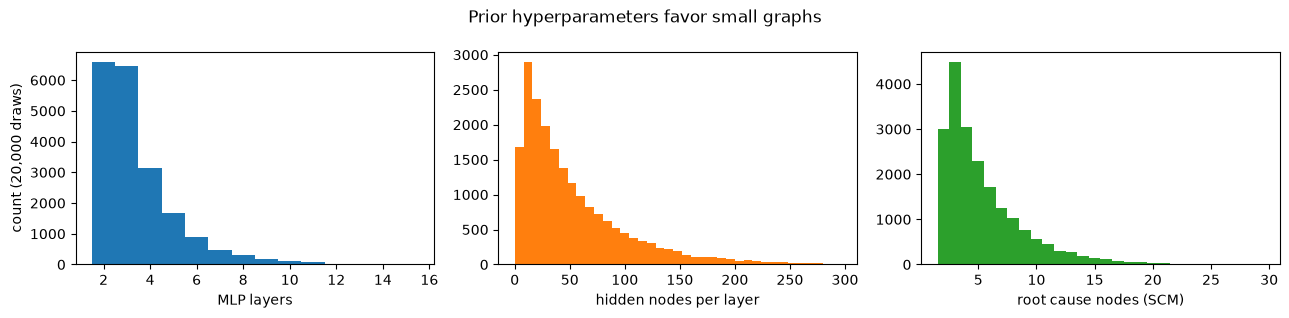

,중앙값,90% 분위,최댓값
층 수,3.0,6.0,26
층당 노드 수,37.0,121.0,823
원인 노드 수,4.0,10.0,45


3층 이하인 비율: 65%


In [16]:
rng = np.random.default_rng(0)
many = [
    prior.sample_group_hyperparameters(rng, spec.MAX_CLASSES, spec.MAX_FEATURES)
    for _ in range(20_000)
]
n_layers = np.array([hp["num_layers"] for hp in many])
hidden = np.array([hp["prior_mlp_hidden_dim"] for hp in many])
causes = np.array([hp["num_causes"] for hp in many])

fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
axes[0].hist(n_layers, bins=np.arange(1.5, 16.5), color="C0")
axes[0].set_xlabel("MLP layers")
axes[1].hist(hidden, bins=np.arange(0, 300, 8), color="C1")
axes[1].set_xlabel("hidden nodes per layer")
axes[2].hist(causes, bins=np.arange(1.5, 30.5), color="C2")
axes[2].set_xlabel("root cause nodes (SCM)")
axes[0].set_ylabel("count (20,000 draws)")
fig.suptitle("Prior hyperparameters favor small graphs")
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(
        {
            "중앙값": [np.median(n_layers), np.median(hidden), np.median(causes)],
            "90% 분위": [
                np.percentile(n_layers, 90),
                np.percentile(hidden, 90),
                np.percentile(causes, 90),
            ],
            "최댓값": [n_layers.max(), hidden.max(), causes.max()],
        },
        index=["층 수", "층당 노드 수", "원인 노드 수"],
    )
)
print(f"3층 이하인 비율: {(n_layers <= 3).mean():.0%}")

대부분 작은 그래프지만 꼬리가 길어서 큰 그래프도 가끔 나옵니다. 그래서 학습한 TabPFN은 데이터가 적으면 단순한 설명을 선호하고, 학습 행이 많으면 더 복잡한 함수도 맞춥니다(부록 B.3.1, Figure 8).

논문 Table 5와 v1 코드는 몇 군데 다릅니다. 논문은 층 수·노드 수를 로그 균등분포와 절단 정규분포를 겹친 분포(TNLU)로 적었지만, v1 설정은 위의 감마분포를 씁니다. 활성화 함수 후보도 논문은 {Tanh, LeakyReLU, ELU, Identity}, v1은 {Tanh, Identity, ReLU}입니다. 이 저장소는 v1을 따랐습니다.

### 3.2 SCM prior — 4.3절, 부록 C.1

SCM 자체는 [`01_scm_primer.ipynb`](01_scm_primer.ipynb)에서 다룹니다.

![TabPFN Figure 2](images/tabpfn_fig2.png)

*그림: 논문 Figure 2. 회색이 관측되는 노드(feature $x$와 target $y$), 흰색이 표에 나오지 않는 노드 $z$입니다. (a) BNN은 입력층이 feature, 출력층이 target입니다. (b) SCM은 그래프의 아무 노드에서나 feature와 target을 고릅니다. (c) prior에서 뽑은 SCM들입니다.*

4.3절의 핵심은 feature와 target을 그래프의 아무 노드에서나 고른다는 점입니다. 그래서 feature가 target의 원인일 수도, 결과일 수도 있고, 표에 없는 노드가 둘 모두에 영향을 줄 수도 있습니다. 논문은 이 방식을 Pearl의 인과 사다리에서 "rung 1.5"라고 부릅니다. 인과 그래프를 추정하지는 않고, 데이터가 SCM 같은 과정에서 나왔다고 가정한 채 관측 데이터로 예측만 합니다.

부록 C.1의 절차가 `prior._sample_mlp_dataset`과 `spec.MLP_HYPERPARAMETERS`의 어디에 해당하는지 정리합니다.

| C.1 단계 | 하는 일 | 하이퍼파라미터 (`spec.py`) |
|---|---|---|
| (1) | 층 수와 층당 노드 수를 뽑아 MLP 모양 그래프를 만든다 | `num_layers`, `prior_mlp_hidden_dim` |
| (2) | 간선 가중치를 정규분포에서 뽑는다 | `init_std` |
| (3) | 간선 일부를 지워 DAG를 만든다 | `prior_mlp_dropout_prob`, `block_wise_dropout` |
| (4) | feature 노드 $k$개와 target 노드 1개를 고른다 | `num_features_used`, `in_clique`, `sort_features`, `y_is_effect` |
| (5) | 노드별 노이즈 크기를 정한다 | `noise_std`, `pre_sample_weights` |
| 행마다 | 원인 노드 값을 뽑고, 층 순서대로 $z \leftarrow W a(z) + b + \epsilon$을 계산한다 | `num_causes`, `prior_mlp_activations` |

실제 prior에서 데이터셋을 뽑아, 논문 Figure 3처럼 feature 두 개씩 짝지어 그립니다. 비교를 위해 실제 데이터셋인 wine(scikit-learn)도 함께 그립니다. prior 데이터셋은 대부분 feature가 수십 개라 세 개만 그리면 구조가 잘 안 보입니다. 그래서 seed를 바꿔 가며 다음 조건에 맞는 첫 데이터셋을 씁니다.

- feature 3~4개, 클래스 2~3개
- 가장 큰 클래스가 60% 이하
- 앞의 feature 3개로 클래스를 꽤 맞힐 수 있음: kNN 정확도가 가장 큰 클래스의 비율보다 0.25 이상 높음 (`02_bnn_primer`의 gain)

SCM은 모든 열이 연속값인 데이터셋과, 일부 열이 범주형으로 바뀐 데이터셋(부록 C.2.5)을 하나씩 고릅니다.

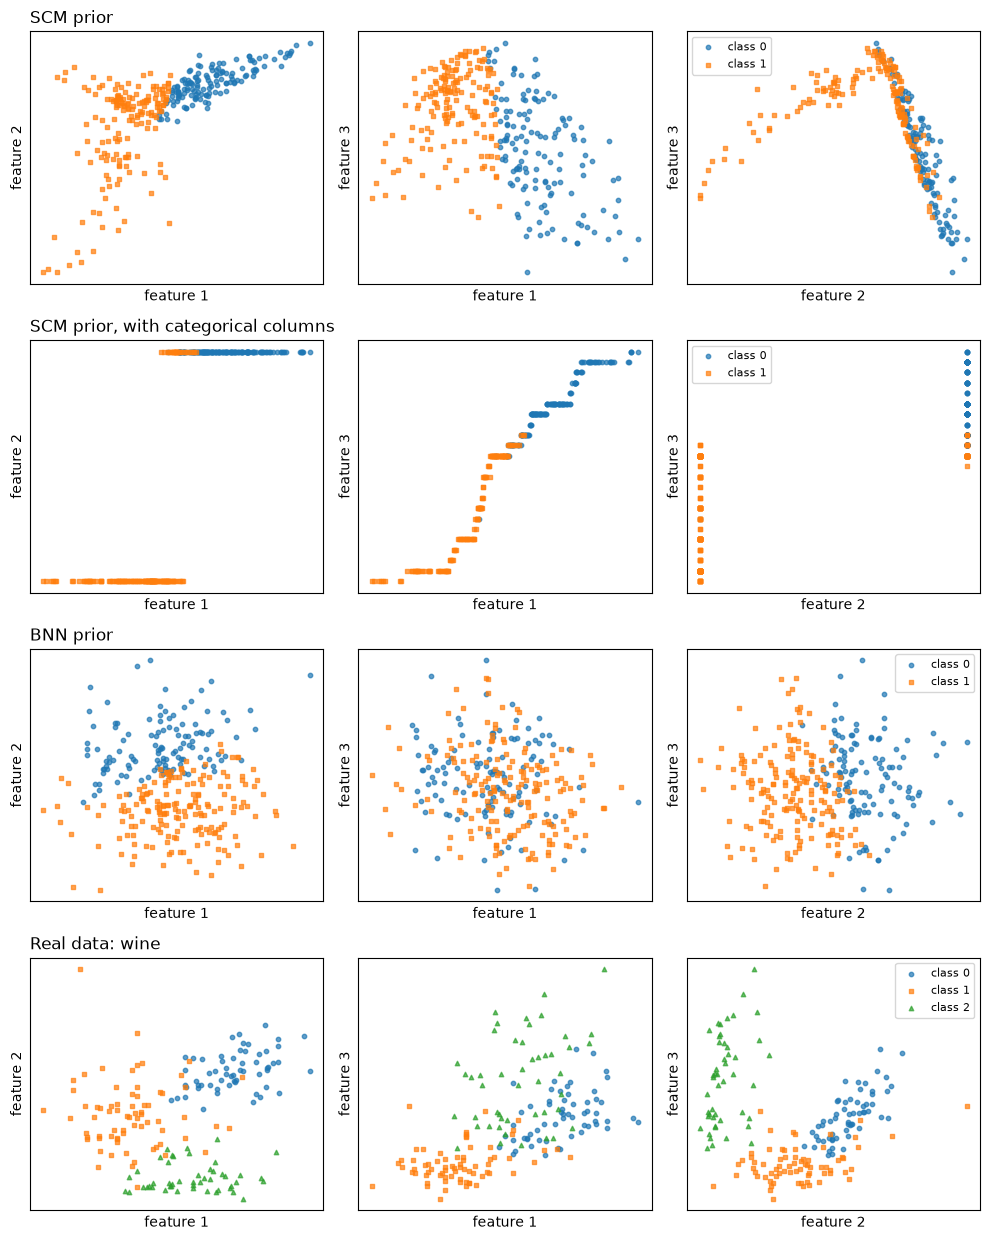

In [17]:
from sklearn.datasets import load_wine
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler


def find_dataset(
    kind: str, categorical: bool = False, n_rows: int = 300
) -> tuple[np.ndarray, np.ndarray]:
    for seed in range(3000):
        sampler = prior.TabPFNPrior(seq_len=n_rows, seed=seed)
        x, y, hp = sampler.sample_group(single_eval_pos=n_rows // 2)
        if prior_kind(hp) != kind or not 3 <= hp["num_features_used"] <= 4:
            continue
        for b in range(x.shape[0]):
            labels = y[b].numpy()
            if (labels < 0).any():
                continue  # 학습에서 무시하는 데이터셋
            labels = labels.astype(int)
            features = x[b, :, :3].numpy()

            # 범주형 열 = 값의 종류가 30개 이하인 열
            n_unique = [len(np.unique(features[:, c])) for c in range(3)]
            has_categorical = min(n_unique) <= 30
            if has_categorical != categorical:
                continue

            n_classes = len(np.unique(labels))
            majority = np.bincount(labels).max() / len(labels)
            if not 2 <= n_classes <= 3 or majority > 0.6:
                continue

            knn_acc = cross_val_score(KNeighborsClassifier(10), features, labels, cv=5).mean()
            if knn_acc - majority > 0.25:
                return features, labels
    raise RuntimeError("조건에 맞는 데이터셋을 찾지 못했습니다")


wine = load_wine()
wine_cols = [
    list(wine.feature_names).index(c) for c in ["alcohol", "flavanoids", "color_intensity"]
]
wine_x = StandardScaler().fit_transform(wine.data[:, wine_cols])

panels = {
    "SCM prior": find_dataset("SCM"),
    "SCM prior, with categorical columns": find_dataset("SCM", categorical=True),
    "BNN prior": find_dataset("BNN"),
    "Real data: wine": (wine_x, wine.target),
}
pairs = [(0, 1), (0, 2), (1, 2)]
markers = ["o", "s", "^"]

fig, axes = plt.subplots(4, 3, figsize=(10, 12.5))
for row, (title, (x, y)) in enumerate(panels.items()):
    for col, (i, j) in enumerate(pairs):
        ax = axes[row, col]
        for c in np.unique(y):
            ax.scatter(
                x[y == c, i], x[y == c, j], s=10, marker=markers[c], alpha=0.7, label=f"class {c}"
            )
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel(f"feature {i + 1}")
        ax.set_ylabel(f"feature {j + 1}")
    axes[row, 0].set_title(title, loc="left", fontsize=12)
    axes[row, 2].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

SCM 데이터셋은 feature끼리 강하게 얽혀 있고, 휘거나 꺾인 비선형 관계가 보입니다. SCM의 feature는 그래프 안의 노드라서, 같은 원인을 공유하면 서로 상관되기 때문입니다. 이웃한 노드를 블록으로 고르는 설정(`in_clique`, 부록 C.2.2)에서는 이런 상관이 더 강해집니다. 범주형 열이 있는 둘째 데이터셋은 값이 몇 개의 층으로 끊어지고, feature 2는 값이 두 개뿐인 열입니다. BNN 데이터셋은 입력을 서로 독립으로 뽑으므로 feature끼리 상관이 없고 점이 둥글게 퍼집니다. 실제 데이터인 wine은 feature 사이의 상관과 클래스별 덩어리를 함께 보입니다.

prior 데이터셋 하나하나가 실제 데이터를 닮을 필요는 없습니다. 이런 여러 모양을 넓게 만들어서, 실제 데이터가 그 범위 안에 들어오게 하는 것이 목적입니다.

### 3.3 BNN prior와 섞기 — 4.4절

BNN prior 자체는 [`02_bnn_primer.ipynb`](02_bnn_primer.ipynb)에서 다룹니다.

BNN prior는 원 PFN 논문의 prior를 이어받은 것으로, 입력층이 feature, 출력층이 target입니다. TabPFN은 데이터셋을 만들 때 같은 확률로 SCM prior 또는 BNN prior를 고릅니다. v1 코드에서는 `is_causal` 하이퍼파라미터가 이 선택이고, 위의 그룹 하이퍼파라미터 표에서 본 것처럼 그룹마다 뽑습니다.

논문 본문에는 없지만 v1 코드는 GP prior도 조금 섞습니다(`prior_bag`). 3.1절에서 뽑은 하이퍼파라미터 20,000개로 비율을 셉니다.

In [18]:
kinds = pd.Series([prior_kind(hp) for hp in many])
display(kinds.value_counts(normalize=True).rename("비율").round(3).to_frame())

,비율
SCM,0.480
BNN,0.478
GP,0.042


SCM과 BNN이 거의 반씩이고, GP는 4% 정도입니다.

부록 B.4는 prior를 바꿔 가며 TabPFN을 학습한 ablation입니다(최종 모델보다 적은 compute). SCM만 쓴 prior가 BNN만 쓴 prior보다 좋고, 둘을 섞어도 SCM만 쓴 것과 큰 차이는 없습니다. `02_bnn_primer` 5절에서 두 prior의 데이터셋이 어떻게 다른지 재 봤습니다.

| prior (B.4, Table 4) | 평균 CE | 평균 ROC AUC |
|---|---|---|
| BNN | 0.811 | 0.865 |
| SCM | 0.771 | 0.881 |
| SCM + BNN (최종 모델) | 0.776 | 0.883 |

### 3.4 다중 클래스 예측 — 4.5절

SCM과 BNN의 target은 연속값 $\hat y$입니다. 분류 데이터셋을 만들려면 $\hat y$를 클래스로 바꿔야 합니다. 논문의 방법은 세 단계입니다.

1. 클래스 수 $N_c$를 뽑습니다.
2. $\hat y$ 값들 가운데 $N_c - 1$개를 무작위로 골라 경계 $B$로 씁니다.
3. 각 $\hat y_i$의 클래스는 $\hat y_i$보다 작은 경계의 개수입니다: $y_i = \sum_j [B_j < \hat y_i]$.

마지막으로 클래스 번호를 섞어서, 번호와 값의 크기 순서를 끊습니다. 행 8개짜리 데이터셋으로 따라가 봅니다. 논문의 예와 같은 경계 $\{-0.1, 0.5\}$가 나오도록 경계 행을 정했습니다.

In [19]:
y_hat = np.array([0.7, -0.4, 0.2, 1.3, -0.1, 0.5, -0.9, 0.3])  # SCM/BNN이 낸 연속값 target

# 1단계: 클래스 수
n_classes = 3

# 2단계: ŷ 값 중 n_classes - 1개를 경계로 고른다 (여기서는 5번째, 6번째 행)
bound_rows = [4, 5]
bounds = y_hat[bound_rows]  # [-0.1, 0.5]

# 3단계: ŷ보다 작은 경계의 개수 = 구간 번호
above_b0 = y_hat > bounds[0]
above_b1 = y_hat > bounds[1]
interval = above_b0.astype(int) + above_b1.astype(int)

# 마지막: 클래스 번호를 섞는다 (구간 0 → 2, 1 → 0, 2 → 1)
class_perm = np.array([2, 0, 1])
y_class = class_perm[interval]

display(
    pd.DataFrame(
        {
            "ŷ": y_hat,
            f"ŷ > {bounds[0]}": above_b0,
            f"ŷ > {bounds[1]}": above_b1,
            "구간 번호": interval,
            "섞은 클래스": y_class,
        },
        index=[f"행 {i + 1}" for i in range(len(y_hat))],
    )
)

,ŷ,ŷ > -0.1,ŷ > 0.5,구간 번호,섞은 클래스
행 1,0.7,True,True,2,1
행 2,-0.4,False,False,0,2
행 3,0.2,True,False,1,0
행 4,1.3,True,True,2,1
행 5,-0.1,False,False,0,2
행 6,0.5,True,False,1,0
행 7,-0.9,False,False,0,2
행 8,0.3,True,False,1,0


$\hat y = -0.1$인 행 5는 경계 $-0.1$보다 크지 않으므로 구간 0, 즉 $(-\infty, -0.1]$에 들어갑니다. 경계를 $\hat y$ 값 가운데서 무작위로 고르므로 클래스 크기는 제각각이 됩니다. 원 PFN의 표 실험이 균형 잡힌 이진 분류만 다뤘던 것과 달리 불균형한 다중 클래스 데이터셋이 자연스럽게 나옵니다. 구현은 `prior.multiclass_rank`이고, 클래스 수는 50% 확률로 2개, 나머지는 2부터 상한까지 균등하게 뽑습니다(v1).

실제 prior에서 데이터셋 2,000개를 뽑아 클래스 수와 가장 큰 클래스의 비율을 봅니다. 학습 때처럼 행 1,152개짜리 데이터셋입니다. 학습 행과 테스트 행의 클래스 집합을 맞추지 못해 학습에서 빼는 데이터셋(정답 -100)은 제외합니다.

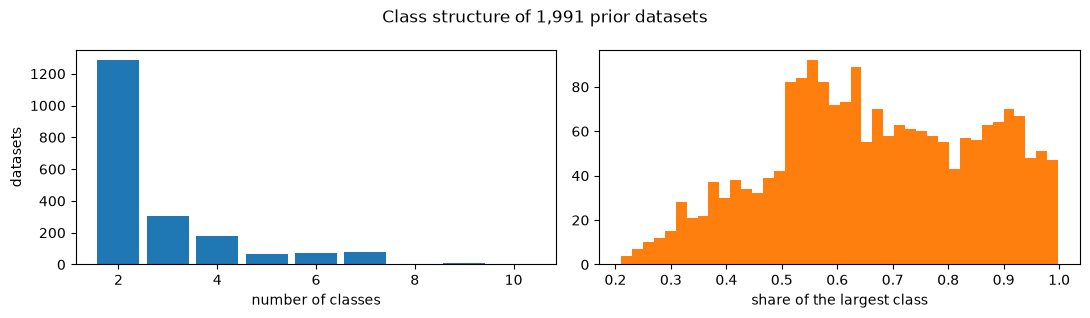

이진 분류 비율: 65%
가장 큰 클래스가 70% 이상인 비율: 44%


In [20]:
sampler = prior.TabPFNPrior(seed=0)  # 학습과 같은 설정: 행 1,152개, feature 100열
n_classes_list, majority_list = [], []
for _ in range(250):  # 그룹 250개 × 데이터셋 8개
    x, y, hp = sampler.sample_group(single_eval_pos=500)
    for labels in y.numpy():
        if (labels < 0).all():
            continue  # 학습에서 무시하는 데이터셋
        counts = np.bincount(labels.astype(int))
        n_classes_list.append(int((counts > 0).sum()))
        majority_list.append(counts.max() / counts.sum())

n_classes_arr, majority_arr = np.array(n_classes_list), np.array(majority_list)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].hist(n_classes_arr, bins=np.arange(1.5, 11.5), color="C0", rwidth=0.85)
axes[0].set_xlabel("number of classes")
axes[0].set_ylabel("datasets")
axes[1].hist(majority_arr, bins=40, color="C1")
axes[1].set_xlabel("share of the largest class")
fig.suptitle(f"Class structure of {len(n_classes_arr):,} prior datasets")
plt.tight_layout()
plt.show()

print(f"이진 분류 비율: {(n_classes_arr == 2).mean():.0%}")
print(f"가장 큰 클래스가 70% 이상인 비율: {(majority_arr >= 0.7).mean():.0%}")

2,000개 중 9개는 학습에서 빼는 데이터셋이라 1,991개가 남았습니다. 이진 분류가 65%로 가장 많고, 클래스가 8개 이상인 데이터셋은 드뭅니다. 가장 큰 클래스의 비율은 0.2부터 1 가까이까지 넓게 퍼져 있어서, 데이터셋의 44%는 가장 큰 클래스가 70% 이상입니다. 실제 표 데이터에서 흔한 클래스 불균형을 prior가 학습 단계에서 미리 보여 주는 셈입니다.

### 3.5 표 데이터 다듬기 — 부록 C.2

부록 C.2는 실제 표 데이터의 특성을 prior에 더한 부분입니다. 이 저장소 구현의 어디에 있는지 함께 정리합니다.

| 부록 | 내용 | 이 구현 |
|---|---|---|
| C.2.1 전처리 | prior 데이터와 실제 데이터 모두 표준화하고 이상치는 log로 누른다. 실제 데이터는 학습 행의 통계만 쓴다. 추론 때는 power transform도 쓴다 | `prior.normalize_data`, `prior.remove_outliers`, `inference._Preprocessor` |
| C.2.2 상관된 feature | 이웃한 노드를 블록으로 골라 feature끼리 상관이 생기게 한다 | `in_clique`, `sort_features` |
| C.2.3 불규칙한 함수 | 간선을 희소하게(블록 단위 포함) 하고, 노이즈 크기를 노드마다 따로 뽑는다 | `prior_mlp_dropout_prob`, `block_wise_dropout`, `pre_sample_weights` |
| C.2.3 입력 분포 | 원인 노드 값을 Gaussian, Zipf, 다변량 분포를 섞어 뽑는다 | 구현 안 함 (원인 노드는 Gaussian만) |
| C.2.3 feature 중요도 | feature마다 가중치를 뽑아 그 feature에서 나가는 간선에 곱한다 | 구현 안 함 |
| C.2.4 결측값 | 따로 처리하지 않고 테스트 때 0으로 바꾼다 | `TabPFNTransformer.forward`의 `nan_to_num`. prior에 결측값을 넣는 것은 공개 체크포인트처럼 껐다(`NAN_PROB = 0`) |
| C.2.5 범주형 feature | 그룹의 20%에서 일부 열을 4.5절처럼 구간 번호로 바꾼다 | `CATEGORICAL_FEATURE_P`, `multiclass_rank` |
| C.2.6 회전 | 학습 때도 feature 열 번호와 클래스 번호를 돌린다 | `RANDOM_FEATURE_ROTATION`, `prior._normalize_labels` |

"구현 안 함"인 두 항목은 논문 본문에는 있지만 이 저장소의 `prior.py`에는 없는 부분입니다. 이 구현은 공개 체크포인트를 만든 v1 설정을 옮겼고, 그 상태로 Table 1을 0.002 차이로 재현했습니다(`04` 노트북).

## 4. 실험 결과 — 5절

### 4.1 toy 문제 — 5.1절

![TabPFN Figure 4](images/tabpfn_fig4.png)

*그림: 논문 Figure 4. feature 2개짜리 toy 데이터셋 4개(위부터 moons, circles, iris의 두 클래스, wine의 두 클래스)에서 튜닝하지 않은 분류기들의 결정 경계입니다. 색이 진할수록 확신이 큽니다.*

결정 트리와 CatBoost는 축에 평행한 계단 모양 경계를, kNN은 들쭉날쭉한 경계를 만듭니다. TabPFN의 경계는 매끄럽고, GP처럼 데이터에서 먼 곳에서는 확신이 낮아집니다(색이 옅어짐). circles처럼 두 클래스가 섞인 곳을 빼면 원 모양도 확신 있게 맞힙니다. 이 그림은 이 저장소에서 아직 재현하지 않았습니다.

### 4.2 실험 설정 — 5.2절

- **데이터셋**: OpenML-CC18 중 샘플 2,000개(학습 1,000개), feature 100개, 클래스 10개 이하인 30개입니다. 본문(Figure 5, Table 1)은 이 중 수치형 feature만 있고 결측값이 없는 18개만 봅니다. prior를 이런 데이터셋에 맞춰 개발했기 때문입니다. 나머지를 포함한 30개 결과는 부록 B.1에 있습니다.
- **baseline**: KNN, 로지스틱 회귀, GBDT 세 개(XGBoost, LightGBM, CatBoost)는 5-fold 교차검증으로 하이퍼파라미터를 무작위 탐색합니다. AutoML 두 개(AutoGluon, Auto-sklearn 2.0)와 딥러닝 두 개(Regularization Cocktails, SAINT)도 비교합니다.
- **프로토콜**: 데이터셋마다 split 5개(학습 50%, 테스트 50%)이고, 지표는 ROC AUC(다중 클래스는 one-vs-one)입니다. baseline에는 30초부터 1시간까지 시간 예산을 줍니다.
- **TabPFN**: 튜닝 없이 앙상블 32개(TabPFN)와 앙상블 없이 forward pass 한 번(TabPFN n.e.)을 봅니다.

### 4.3 결과 — Table 1

18개 데이터셋에서 baseline에 1시간을 준 결과입니다. 논문 Table 1의 값을 옮겼습니다.

,평균 ROC AUC,평균 accuracy,평균 CE,시간 (s)
LightGBM,0.920000,0.862000,0.750000,3280
CatBoost,0.924000,0.864000,0.747000,3746
XGBoost,0.924000,0.866000,0.759000,3364
Auto-sklearn 2.0,0.929000,0.870000,0.813000,3601
AutoGluon,0.930000,0.881000,0.714000,3077
TabPFN n.e.,0.932000,0.873000,0.727000,0.0519
TabPFN,0.934000,0.879000,0.716000,0.6172
TabPFN + AutoGluon,0.934000,0.886000,0.711000,3077


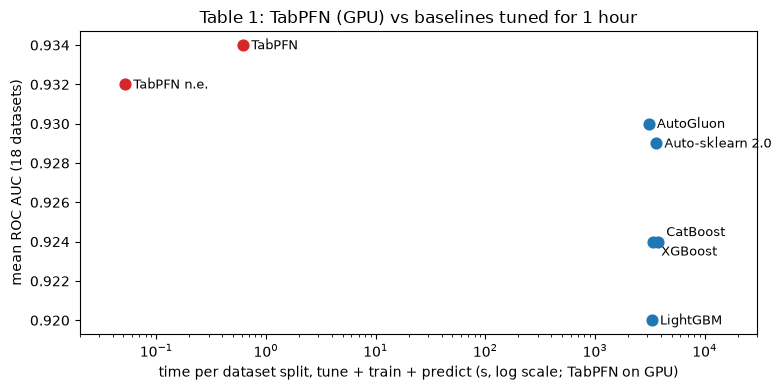

In [21]:
table1 = pd.DataFrame(
    {
        "평균 ROC AUC": [0.920, 0.924, 0.924, 0.929, 0.930, 0.932, 0.934, 0.934],
        "평균 accuracy": [0.862, 0.864, 0.866, 0.870, 0.881, 0.873, 0.879, 0.886],
        "평균 CE": [0.750, 0.747, 0.759, 0.813, 0.714, 0.727, 0.716, 0.711],
        # 튜닝 + 학습 + 예측 시간. baseline은 CPU, TabPFN은 GPU (CPU 시간은 아래 셀)
        "시간 (s)": [3280, 3746, 3364, 3601, 3077, 0.0519, 0.6172, 3077],
    },
    index=[
        "LightGBM",
        "CatBoost",
        "XGBoost",
        "Auto-sklearn 2.0",
        "AutoGluon",
        "TabPFN n.e.",
        "TabPFN",
        "TabPFN + AutoGluon",
    ],
)
display(table1.style.format({"시간 (s)": "{:g}"}))

# 라벨이 겹치지 않도록 점마다 글자 위치를 조금씩 옮긴다
label_offsets = {"CatBoost": (6, 4), "XGBoost": (6, -10)}
fig, ax = plt.subplots(figsize=(8, 4))
for name, row in table1.drop(index="TabPFN + AutoGluon").iterrows():
    is_tabpfn = name.startswith("TabPFN")
    ax.scatter(row["시간 (s)"], row["평균 ROC AUC"], s=60, color="C3" if is_tabpfn else "C0")
    offset = label_offsets.get(name, (6, -3))
    ax.annotate(
        name,
        (row["시간 (s)"], row["평균 ROC AUC"]),
        textcoords="offset points",
        xytext=offset,
        fontsize=9,
    )
ax.set_xscale("log")
ax.set_xlim(0.02, 30_000)
ax.set_xlabel("time per dataset split, tune + train + predict (s, log scale; TabPFN on GPU)")
ax.set_ylabel("mean ROC AUC (18 datasets)")
ax.set_title("Table 1: TabPFN (GPU) vs baselines tuned for 1 hour")
plt.tight_layout()
plt.show()

TabPFN은 GPU에서 1초 안에 평균 ROC AUC 0.934를 내서, 1시간 튜닝한 AutoGluon(0.930)과 Auto-sklearn 2.0(0.929)보다 조금 높고, 튜닝한 GBDT(0.920~0.924)보다는 확실히 높습니다. 앙상블 없이 forward pass 한 번만 해도 0.932입니다. TabPFN과 AutoGluon의 예측을 평균하면 accuracy와 CE가 가장 좋아집니다. 두 방법이 잘하는 데이터셋이 서로 달라서 오류의 상관이 낮기 때문입니다(부록 Figure 11).

초록의 "230배, 5,700배 빠르다"는 TabPFN n.e.를 5분 예산의 가장 강한 baseline과 비교한 값입니다(5.2절). 두 성능이 비슷하므로 시간만 나누면 됩니다.

In [22]:
baseline_budget = 5 * 60  # 5분 예산 baseline이 TabPFN n.e.와 비슷한 성능을 낸다 (5.2절)
tabpfn_ne_cpu = 1.301  # Table 1, TabPFN n.e.의 CPU 시간 (s)
tabpfn_ne_gpu = 0.0519  # Table 1, TabPFN n.e.의 GPU 시간 (s)
print(f"CPU: {baseline_budget / tabpfn_ne_cpu:.0f}배")
print(f"GPU: {baseline_budget / tabpfn_ne_gpu:,.0f}배")

CPU: 231배
GPU: 5,780배


이 저장소에서 논문 규모로 학습한 모델은 같은 18개 데이터셋에서 0.932(앙상블 없이 0.928)를 냈습니다. 어떻게 학습하고 평가했는지는 [`04_tabpfn_reproduction`](04_tabpfn_reproduction.ipynb)에 있습니다.

이 값들은 데이터셋 평균입니다. 논문도 강조하듯 모든 데이터셋에서 이기는 방법은 없고, 기본값 baseline에 지는 데이터셋도 있습니다.

### 4.4 그 밖의 결과 — 5.2절, 부록 B

| 실험 | 결과 | 이 저장소 |
|---|---|---|
| 30개 데이터셋 (B.1, Table 2) | 범주형 feature나 결측값이 있는 데이터셋까지 넣으면 TabPFN 0.894, AutoGluon 0.895로 우위가 사라진다 | 아직 |
| 데이터셋 특성별 (B.1, Figure 6) | 범주형 feature와 결측값이 없을 때 특히 강하다. 이진·다중 클래스는 비슷하다 | 아직 |
| OpenML-AutoML Benchmark (B.2) | 데이터셋당 CPU 4.4초로 60분 baseline들보다 평균 CE와 accuracy가 좋다 | 아직 |
| 학습 때보다 큰 데이터셋 (Figure 10) | 학습 때 최대 1,024행만 봤지만 학습 행 5,000개까지 성능이 평평해지지 않고 오른다 | 아직 |
| 귀납 편향 (B.3) | 매끄러운 함수를 선호하고, 무의미한 feature가 늘면 성능이 떨어지며, feature 회전에는 GBDT보다 덜 민감하다 | 아직 |
| prior ablation (B.4, Table 4) | SCM 0.881, BNN 0.865, 둘 섞기 0.883 | 아직 (3.3절 표) |
| 검증 데이터셋 149개 (B.5) | 수치형 데이터셋에서 강하다는 결론이 유지된다 | 아직 |

## 5. 한계 — 부록 A

논문이 직접 적은 한계는 다섯 가지입니다.

**1. 비용이 학습 행 수의 제곱으로 늘어납니다.** attention 점수가 $n^2 + n \cdot m$개이기 때문입니다. 논문은 10만 행이 넘으면 당시 소비자용 GPU에서 추론이 어렵다고 적었습니다. 점수 행렬을 메모리에 다 만든다고 하면 층 하나에 필요한 크기는 다음과 같습니다(head 4개, fp16 기준).

In [23]:
rows = []
for n in [1_000, 10_000, 100_000]:
    m = n  # 테스트 행도 같은 수
    scores = spec.NHEAD * (n**2 + n * m)  # head 4개의 attention 점수
    rows.append(
        {
            "학습 행 n": f"{n:,}",
            "테스트 행 m": f"{m:,}",
            "점수 개수": f"{scores:,}",
            "fp16 메모리": f"{scores * 2 / 1e9:,.2f} GB",
        }
    )
display(pd.DataFrame(rows))

,학습 행 n,테스트 행 m,점수 개수,fp16 메모리
0,"1,000","1,000","8,000,000",0.02 GB
1,"10,000","10,000","800,000,000",1.60 GB
2,"100,000","100,000","80,000,000,000",160.00 GB


행 수가 10배 늘면 메모리는 100배 늘어납니다. 요즘 쓰는 flash attention 같은 커널은 점수 행렬을 통째로 만들지 않아 메모리는 줄지만, 계산량은 여전히 제곱으로 늘어납니다.

**2. feature 100개, 클래스 10개가 상한입니다.** `x_encoder`의 입력 크기와 decoder의 출력 크기가 고정되어 있기 때문입니다.

In [24]:
print("x_encoder 입력 크기 (최대 feature 수):", paper_model.x_encoder.in_features)
print("decoder 출력 크기 (최대 클래스 수):  ", paper_model.decoder[-1].out_features)

x_encoder 입력 크기 (최대 feature 수): 100
decoder 출력 크기 (최대 클래스 수):   10


**3. 범주형 feature와 결측값에 약합니다.** prior를 수치형 데이터셋에 맞춰 개발했기 때문입니다. 수치형 18개에서는 TabPFN(0.934)이 AutoGluon(0.930)보다 높지만, 30개 전체에서는 0.894와 0.895로 비슷해집니다(Table 2).

**4. 무의미한 feature에 약합니다.** prior에 정보 없는 feature가 많은 데이터셋이 드물어서, 이런 feature를 더하면 성능이 떨어집니다(B.3.2). LightGBM은 거의 영향을 받지 않습니다.

**5. 예측만 보면 baseline이 더 빠를 수 있습니다.** baseline은 학습과 예측을 따로 하지만 TabPFN은 둘을 forward pass 한 번에 같이 합니다. 그래서 학습이 끝난 baseline의 예측 시간만 비교하면, 앙상블 32개를 쓰는 TabPFN(0.62초)은 GBDT(0.02~0.08초)보다 느립니다. 앙상블 없는 TabPFN은 GBDT와 비슷합니다(Table 2, 30개 데이터셋 기준).

| | 예측 시간 (s) |
|---|---|
| CatBoost | 0.017 |
| XGBoost | 0.069 |
| LightGBM | 0.082 |
| TabPFN n.e. (학습 + 예측, GPU) | 0.052 |
| TabPFN (학습 + 예측, GPU) | 0.617 |
| Auto-sklearn 2.0 | 1.224 |
| AutoGluon | 21.18 |

후속 논문인 TabPFN v2(Hollmann et al., *Nature* 2025)는 prior와 구조를 바꿔 더 큰 데이터셋과 범주형 feature, 결측값을 다루도록 확장했습니다. 그 내용은 [`03_tabpfn_v2`](../03_tabpfn_v2/03_tabpfn_v2_paper_walkthrough.ipynb)에서 다룹니다.

## 6. 정리

| 논문 | 핵심 | 이 저장소 코드 |
|---|---|---|
| 2절 | PFN과 같은 손실로 prior의 PPD를 근사한다 | `train.train_tabpfn`, `model.classification_loss` |
| 3절, E.2 | 테스트 행은 학습 행에만 attend한다 ($n^2 + n \cdot m$) | `model.TabPFNLayer._attend` |
| E.2 | feature를 100열까지 0으로 채우고 $100/k$배 한다 | `prior.TabPFNPrior.sample_group`, `inference._Preprocessor` |
| 3절, C.2.6 | 열 회전, 클래스 회전, power transform으로 앙상블 32개 | `inference.TabPFNClassifier` |
| 4.1, 4.2 | 하이퍼파라미터도 분포에서 뽑고, 작은 그래프가 자주 나오게 한다 | `spec.MLP_HYPERPARAMETERS`, `prior.sample_group_hyperparameters` |
| 4.3, 4.4 | SCM과 BNN을 반씩 섞는다 (v1은 GP도 4%) | `prior._sample_mlp_dataset`, `prior._sample_gp_group` |
| 4.5 | 연속값 target을 무작위 경계로 잘라 불균형한 클래스로 만든다 | `prior.multiclass_rank` |
| 5절 | 18개 데이터셋에서 1시간 튜닝한 AutoML과 비슷한 성능을 1초 안에 | `evaluate`, [`04_tabpfn_reproduction`](04_tabpfn_reproduction.ipynb) |

다음 노트북 [`04_tabpfn_reproduction`](04_tabpfn_reproduction.ipynb)에서는 이 구성으로 논문 규모의 TabPFN을 학습하고 Table 1과 비교합니다.